In [1]:
!pip install -q langchain langchain-groq pypdf pydantic pandas matplotlib seaborn

In [2]:
!pip install -q groq pypdf pandas matplotlib seaborn
print("Librerías listas.")

Librerías listas.


[Agente Ingesta PDF] Leyendo y mapeando páginas de: discurso-dina.pdf (A partir de la página 4)

[Agente Temático Autónomo] Procesando los 174 fragmentos a partir de la página 4...



,id_fragmento,pagina_pdf,categoria_principal,peso_conceptual,resumen_enfoque
0,F01,4,Social,3,Menciones sobre directrices y políticas públic...
1,F02,4,Social,3,Menciones sobre directrices y políticas públic...
2,F03,5,Social,3,Menciones sobre directrices y políticas públic...
3,F04,5,Seguridad Ciudadana,5,Menciones sobre directrices y políticas públic...
4,F05,5,Social,3,Menciones sobre directrices y políticas públic...
...,...,...,...,...,...
169,F0170,72,Infraestructura,7,Menciones sobre directrices y políticas públic...
170,F0171,72,Social,3,Menciones sobre directrices y políticas públic...
171,F0172,73,Social,3,Menciones sobre directrices y políticas públic...
172,F0173,73,Social,3,Menciones sobre directrices y políticas públic...


/tmp/ipykernel_702/4126332731.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_prioridades, x='categoria_principal', y='peso_conceptual', palette='crest')


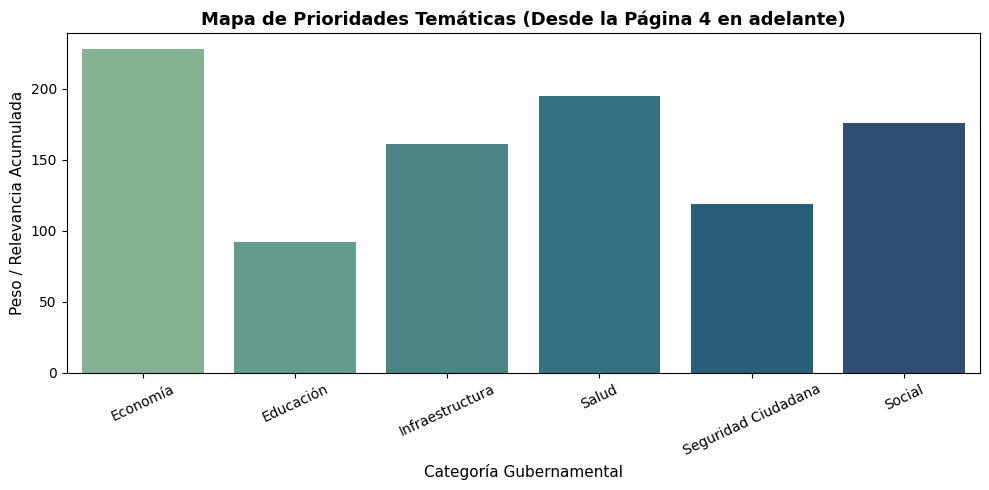

In [7]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from groq import Groq
from pypdf import PdfReader

# 1. Configura tu API Key de Groq aquí
client = Groq(api_key="aaaaaaaaaaa")

# 2. Función de lectura que omite las páginas anteriores a la 4 (índice/portada)
def extraer_fragmentos_con_pagina(ruta_pdf: str, tamano_chunk: int = 150, pagina_inicio: int = 4):
    print(f"[Agente Ingesta PDF] Leyendo y mapeando páginas de: {ruta_pdf} (A partir de la página {pagina_inicio})")
    reader = PdfReader(ruta_pdf)
    fragmentos_con_meta = []

    for num_pag, page in enumerate(reader.pages, start=1):
        if num_pag < pagina_inicio:
            continue  # Salta las páginas anteriores al contenido principal

        texto_pag = page.extract_text()
        if texto_pag:
            palabras = texto_pag.split()
            for i in range(0, len(palabras), tamano_chunk):
                chunk_texto = " ".join(palabras[i:i + tamano_chunk])
                fragmentos_con_meta.append({
                    "pagina": num_pag,
                    "texto": chunk_texto
                })
    return fragmentos_con_meta

# 3. Función de respaldo local (en caso de restricciones en la API)
def clasificacion_respaldo_local(texto: str) -> dict:
    texto_lower = texto.lower()
    keywords = {
        "Salud": ["hospital", "salud", "médico", "medicamento", "posta", "enfermedad", "sanitario"],
        "Educación": ["colegio", "escuela", "educación", "docente", "maestro", "universidad", "estudiante"],
        "Economía": ["inflación", "pbi", "crecimiento", "presupuesto", "inversión", "economía", "empleo"],
        "Seguridad Ciudadana": ["policía", "delincuencia", "seguridad", "crimen", "narcotráfico", "robo"],
        "Infraestructura": ["carretera", "puente", "construcción", "obra", "vial", "agua", "saneamiento"],
        "Social": ["programa", "comedor", "pobreza", "bono", "ayuda social", "población"]
    }
    conteo = {cat: sum(1 for p in w if p in texto_lower) for cat, w in keywords.items()}
    mejor_cat = max(conteo, key=conteo.get)
    peso = min(max(conteo[mejor_cat] * 2 + 3, 3), 10)
    if max(conteo.values()) == 0:
        mejor_cat = "Social"
        peso = 3
    return {
        "categoria_principal": mejor_cat,
        "peso_conceptual": peso,
        "resumen_enfoque": "Menciones sobre directrices y políticas públicas del sector."
    }

# 4. Carga y fragmentación omitiendo las primeras 3 páginas
ruta_pdf = "discurso-dina.pdf"
chunks_data = extraer_fragmentos_con_pagina(ruta_pdf, tamano_chunk=150, pagina_inicio=4)

# 5. Procesamiento con el Agente Autónomo
resultados_analisis = []
print(f"\n[Agente Temático Autónomo] Procesando los {len(chunks_data)} fragmentos a partir de la página 4...\n")

for idx, item in enumerate(chunks_data):
    chunk = item["texto"]
    pag_origen = item["pagina"]

    try:
        completion = client.chat.completions.create(
            model="gemma2-9b-it",
            messages=[
                {
                    "role": "system",
                    "content": "Eres un agente experto en análisis político. Clasifica el texto en una de estas categorías: Economía, Salud, Educación, Seguridad Ciudadana, Infraestructura, Social. Devuelve estrictamente un JSON con las claves: 'categoria_principal', 'peso_conceptual' (número del 1 al 10), y 'resumen_enfoque'."
                },
                {
                    "role": "user",
                    "content": f"Analiza el siguiente fragmento:\n{chunk}"
                }
            ],
            response_format={"type": "json_object"}
        )
        res = json.loads(completion.choices[0].message.content)
    except Exception as e:
        # Respaldo automático si hay algún problema con la API
        res = clasificacion_respaldo_local(chunk)

    resultados_analisis.append({
        "id_fragmento": f"F0{idx+1}",
        "pagina_pdf": pag_origen, # Registra la página exacta (empezando desde la 4)
        **res
    })

# 6. Mostrar la tabla consolidada completa
df_resultados = pd.DataFrame(resultados_analisis)
display(df_resultados)

# 7. Generación del Gráfico de Prioridades Temáticas Global
if not df_resultados.empty:
    df_prioridades = df_resultados.groupby('categoria_principal')['peso_conceptual'].sum().reset_index()

    plt.figure(figsize=(10, 5))
    sns.barplot(data=df_prioridades, x='categoria_principal', y='peso_conceptual', palette='crest')
    plt.title('Mapa de Prioridades Temáticas (Desde la Página 4 en adelante)', fontsize=13, fontweight='bold')
    plt.xlabel('Categoría Gubernamental', fontsize=11)
    plt.ylabel('Peso / Relevancia Acumulada', fontsize=11)
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()